<div align="center">
<h1>Uji Zero-Shot Domain Shift ke RDD-indo-v2</h1>
<p>Skenario 3 (data baru): bobot N-RDD2024 (sumber, Asia) diuji langsung pada RDD-indo-v2 (target, 308 citra test) tanpa fine-tuning. Adaptasi dari notebook 05_zero_shot_indonesia.ipynb; urutan kelas target identik dengan data lama sehingga mapping sama.</p>
</div>

In [1]:
from pathlib import Path
from collections import Counter

REPO = next((q for q in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (q / 'data' / 'RDD-indo-v2').exists()), Path.cwd().resolve())
print('REPO:', REPO)
SRC_NAMES = ['Longitudinal_Crack', 'Transverse_Crack', 'Alligator_Crack', 'Pothole', 'manhole', 'patchy_road']
TGT_NAMES = ['alligator crack', 'longitudinal crack', 'manhole', 'patchy road', 'pothole', 'tranverse crack']
INDO = REPO / 'data/RDD-indo-v2'

for split in ['valid', 'test']:
    imgs = list((INDO / split / 'images').glob('*'))
    lbls = list((INDO / split / 'labels').glob('*.txt'))
    c, empty = Counter(), 0
    for f in lbls:
        ls = [l.strip() for l in f.read_text().splitlines() if l.strip()]
        if not ls:
            empty += 1
        for l in ls:
            c[int(l.split()[0])] += 1
    print(f'{split}: {len(imgs)} images, {len(lbls)} label files, {empty} empty')
    print('  instances per target-id:', dict(sorted(c.items())), f"-> total {sum(c.values())}")
    print('  artinya:', {TGT_NAMES[k]: v for k, v in sorted(c.items())})

REPO: /mnt/Data/01_Akademik/TA-Project
valid: 6 images, 6 label files, 0 empty
  instances per target-id: {0: 4, 1: 3, 3: 1, 4: 1, 5: 6} -> total 15
  artinya: {'alligator crack': 4, 'longitudinal crack': 3, 'patchy road': 1, 'pothole': 1, 'tranverse crack': 6}
test: 308 images, 308 label files, 26 empty
  instances per target-id: {0: 53, 1: 250, 2: 4, 3: 28, 4: 125, 5: 125} -> total 585
  artinya: {'alligator crack': 53, 'longitudinal crack': 250, 'manhole': 4, 'patchy road': 28, 'pothole': 125, 'tranverse crack': 125}


## ***Pemetaan Kelas***
---
Urutan kelas sumber dan target berbeda (nama kelas v2 identik dengan data lama). Label v2 dipetakan ke urutan sumber sebelum evaluasi.

In [2]:
import shutil

TGT2SRC = {0: 2, 1: 0, 2: 4, 3: 5, 4: 3, 5: 1}  # target-id -> source-id (cocok via nama kelas, sama seperti notebook 05)
print('mapping target->source:', TGT2SRC)
assert [SRC_NAMES[TGT2SRC[i]] for i in range(6)] == ['Alligator_Crack', 'Longitudinal_Crack', 'manhole', 'patchy_road', 'Pothole', 'Transverse_Crack']

EV = REPO / 'runs/rdd_yolov8n_local/evaluation/zero_shot_indo_v2'
EV.mkdir(parents=True, exist_ok=True)
REM = REPO / 'runs/rdd_yolov8n_local/indo_v2_remapped'
if REM.exists():
    shutil.rmtree(REM)
for split in ['test', 'valid']:
    (REM / split / 'images').mkdir(parents=True)
    (REM / split / 'labels').mkdir(parents=True)
    for img in (INDO / split / 'images').iterdir():
        (REM / split / 'images' / img.name).symlink_to(img.resolve())
    for lf in (INDO / split / 'labels').glob('*.txt'):
        out = []
        for l in lf.read_text().splitlines():
            if not l.strip():
                continue
            p = l.split()
            out.append(f"{TGT2SRC[int(p[0])]} " + ' '.join(p[1:]))
        (REM / split / 'labels' / lf.name).write_text('\n'.join(out) + ('\n' if out else ''))

(REM / 'indo_v2_remapped.yaml').write_text(
    f"path: {REM}\ntrain: test/images\ntest: test/images\nval: valid/images\nnc: 6\nnames: {SRC_NAMES}\n")
print('remapped yaml:', REM / 'indo_v2_remapped.yaml')
print('test images:', len(list((REM / 'test/images').iterdir())), '| test labels:', len(list((REM / 'test/labels').glob('*.txt'))))
print('valid images:', len(list((REM / 'valid/images').iterdir())), '| valid labels:', len(list((REM / 'valid/labels').glob('*.txt'))))

mapping target->source: {0: 2, 1: 0, 2: 4, 3: 5, 4: 3, 5: 1}
remapped yaml: /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/indo_v2_remapped/indo_v2_remapped.yaml
test images: 308 | test labels: 308
valid images: 6 | valid labels: 6


## ***Prediksi Zero-Shot***
---
Val tiap bobot pada split test RDD-indo-v2 (conf=0.001, iou=0.6, sama seperti Skenario 1 dan notebook 05).

In [3]:
import sys, json, torch
sys.path.insert(0, str(REPO / 'code/models'))
from ultralytics import YOLO
_PATCHED = False
def ensure_patch():
    global _PATCHED
    if not _PATCHED:
        from custom_modules import patch_ultralytics
        patch_ultralytics()
        _PATCHED = True
        print('patch custom aktif (wajib untuk PD/RD)')

DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)
DATA = str(REM / 'indo_v2_remapped.yaml')
WEIGHTS = {
    'yolov8n': REPO / 'runs/rdd_yolov8n_local/experiments/yolov8n_class_weight/weights/best.pt',
    'yolov12n': REPO / 'runs/rdd_yolov8n_local/experiments/yolov12n_class_weight/weights/best.pt',
    'yolov26n': REPO / 'runs/rdd_yolov8n_local/experiments/yolov26n_class_weight/weights/best.pt',
    'yolov8_pd': REPO / 'runs/rdd_yolov8n_local/experiments/yolov8_pd_class_weight/weights/best.pt',
    'yolo_rd': REPO / 'runs/rdd_yolov8n_local/experiments/yolo_rd_class_weight/weights/best.pt',
}
for k, v in WEIGHTS.items():
    print(k, 'OK' if v.exists() else f'HILANG: {v}')
SRC_TEST = {'yolov8n': 0.648, 'yolov12n': 0.654, 'yolov26n': 0.625, 'yolov8_pd': 0.646, 'yolo_rd': 0.661}
ZS = {}


def run_zs(name):
    if name in ('yolov8_pd', 'yolo_rd'):
        ensure_patch()
    m = YOLO(str(WEIGHTS[name]))
    r = m.val(data=DATA, split='test', imgsz=640, conf=0.001, iou=0.6, verbose=False, device=DEVICE)
    d = {'P': float(r.box.p.mean()), 'R': float(r.box.r.mean()), 'mAP50': float(r.box.map50), 'mAP5095': float(r.box.map)}
    ZS[name] = d
    print(f"{name}: P={d['P']:.3f} R={d['R']:.3f} mAP50={d['mAP50']:.3f} mAP50-95={d['mAP5095']:.3f}")
    return d

device: 0
yolov8n OK
yolov12n OK
yolov26n OK
yolov8_pd OK
yolo_rd OK


In [4]:
run_zs('yolov8n')

Ultralytics 8.4.115 🚀 Python-3.12.14 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 5857MiB)
Model summary (fused): 73 layers, 3,006,818 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.0 ms, read: 117.0±33.5 MB/s, size: 64.6 KB)
val: Scanning /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/indo_v2_remapped/test/labels... 308 images, 26 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 308/308 1.5Kit/s 0.2s<0.4s
val: New cache created: /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/indo_v2_remapped/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 7.3it/s 2.7s0.1s
                   all        308        585      0.205       0.21      0.145     0.0571
Speed: 1.3ms preprocess, 5.1ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to /mnt/Data/01_Akademik/TA-Project/code/runs/detect/val-36
yolov8n: P=0.205 R=0.210 mAP50=0.145 mAP50-95=0.0

{'P': 0.20479956139536248,
 'R': 0.2103562425944703,
 'mAP50': 0.14536922399411112,
 'mAP5095': 0.057142407509470014}

In [5]:
run_zs('yolov12n')

Ultralytics 8.4.115 🚀 Python-3.12.14 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 5857MiB)
YOLOv12n summary (fused): 159 layers, 2,557,898 parameters, 0 gradients, 7.3 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.0 ms, read: 435.0±181.0 MB/s, size: 63.5 KB)
val: Scanning /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/indo_v2_remapped/test/labels.cache... 308 images, 26 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 308/308 99.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 6.0it/s 3.3s0.1s
                   all        308        585      0.256      0.219      0.172     0.0659
Speed: 1.2ms preprocess, 7.0ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to /mnt/Data/01_Akademik/TA-Project/code/runs/detect/val-37
yolov12n: P=0.256 R=0.219 mAP50=0.172 mAP50-95=0.066


{'P': 0.2564291336057835,
 'R': 0.21850853548966753,
 'mAP50': 0.17215378566139464,
 'mAP5095': 0.06586652244787115}

In [6]:
run_zs('yolov26n')

Ultralytics 8.4.115 🚀 Python-3.12.14 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 5857MiB)


YOLO26n summary (fused): 122 layers, 2,376,006 parameters, 0 gradients, 5.3 GFLOPs


val: Fast image access ✅ (ping: 0.1±0.0 ms, read: 630.5±49.6 MB/s, size: 73.8 KB)



val: Scanning /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/indo_v2_remapped/test/labels.cache... 308 images, 26 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 308/308 161.5Mit/s 0.0s


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 5% ╸─────────── 1/20 1.4it/s 0.2s<13.9s

...

                   all        308        585      0.201      0.191      0.136     0.0549


Speed: 1.0ms preprocess, 4.9ms inference, 0.0ms loss, 0.2ms postprocess per image


Results saved to /mnt/Data/01_Akademik/TA-Project/code/runs/detect/val-33


yolov26n: P=0.201 R=0.191 mAP50=0.136 mAP50-95=0.055


{'P': 0.20132075609966357,
 'R': 0.19141501495691216,
 'mAP50': 0.1362689031839787,
 'mAP5095': 0.054901739805860765}

In [7]:
run_zs('yolov8_pd')

patch custom aktif (wajib untuk PD/RD)
Ultralytics 8.4.115 🚀 Python-3.12.14 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 5857MiB)


D:\Faaris\Project-TA\road-damage-detection-ta\code\models\YOLOv8-pd summary: 156 layers, 2,468,085 parameters, 0 gradients, 7.6 GFLOPs


val: Fast image access ✅ (ping: 0.1±0.0 ms, read: 473.6±124.3 MB/s, size: 50.6 KB)



val: Scanning /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/indo_v2_remapped/test/labels.cache... 308 images, 26 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 308/308 161.5Mit/s 0.0s


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 5% ╸─────────── 1/20 1.2it/s 0.2s<15.5s

...

                   all        308        585      0.193      0.188      0.149     0.0574


Speed: 0.9ms preprocess, 6.7ms inference, 0.0ms loss, 0.5ms postprocess per image


Results saved to /mnt/Data/01_Akademik/TA-Project/code/runs/detect/val-34


yolov8_pd: P=0.193 R=0.188 mAP50=0.149 mAP50-95=0.057


{'P': 0.19273043316221394,
 'R': 0.18783416929931449,
 'mAP50': 0.1491834464953517,
 'mAP5095': 0.05737861740597658}

In [8]:
run_zs('yolo_rd')

Ultralytics 8.4.115 🚀 Python-3.12.14 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 5857MiB)


D:\Faaris\Project-TA\road-damage-detection-ta\code\models\YOLO-rd summary: 163 layers, 7,086,104 parameters, 0 gradients, 12.8 GFLOPs


val: Fast image access ✅ (ping: 0.1±0.0 ms, read: 498.9±124.3 MB/s, size: 55.9 KB)



val: Scanning /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/indo_v2_remapped/test/labels.cache... 308 images, 26 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 308/308 161.5Mit/s 0.0s


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 5% ╸─────────── 1/20 1.2it/s 0.3s<16.4s

...

                   all        308        585      0.235      0.185      0.149     0.0602


Speed: 1.4ms preprocess, 9.6ms inference, 0.0ms loss, 0.3ms postprocess per image


Results saved to /mnt/Data/01_Akademik/TA-Project/code/runs/detect/val-35


yolo_rd: P=0.235 R=0.185 mAP50=0.149 mAP50-95=0.060


{'P': 0.235392640336576,
 'R': 0.18500747283594854,
 'mAP50': 0.1494641260890989,
 'mAP5095': 0.06021215659177833}

## ***Domain Gap***
---
Perbandingan mAP50 test sumber vs zero-shot RDD-indo-v2 per model.

In [9]:
import pandas as pd

rows = [{'model': k, 'src_test': SRC_TEST[k], 'indo_v2_zs': v['mAP50'], 'drop_abs': v['mAP50'] - SRC_TEST[k],
         'drop_rel_pct': 100 * (v['mAP50'] - SRC_TEST[k]) / SRC_TEST[k]} for k, v in ZS.items()]
df = pd.DataFrame(rows).sort_values('indo_v2_zs', ascending=False).reset_index(drop=True)
print(df.round(3).to_string(index=False))
(EV / 'domain_gap.csv').parent.mkdir(parents=True, exist_ok=True)
df.to_csv(EV / 'domain_gap.csv', index=False)
print('tersimpan:', EV / 'domain_gap.csv')

    model  src_test  indo_v2_zs  drop_abs  drop_rel_pct
 yolov12n     0.654       0.172    -0.482       -73.677
  yolo_rd     0.661       0.149    -0.512       -77.388
yolov8_pd     0.646       0.149    -0.497       -76.907
  yolov8n     0.648       0.145    -0.503       -77.566
 yolov26n     0.625       0.136    -0.489       -78.197
tersimpan: /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/evaluation/zero_shot_indo_v2/domain_gap.csv


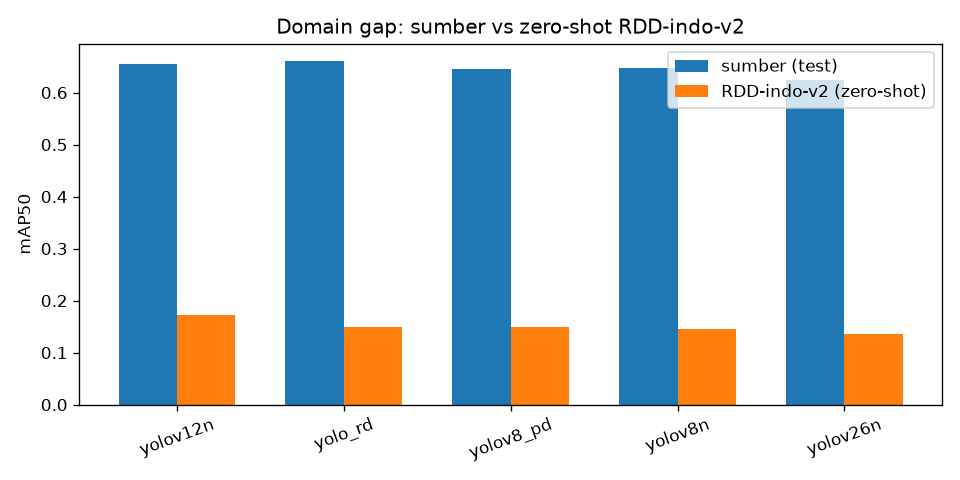

In [10]:
import matplotlib.pyplot as plt

x = range(len(df))
w = 0.35
plt.figure(figsize=(8, 4))
plt.bar([i - w / 2 for i in x], df['src_test'], width=w, label='sumber (test)')
plt.bar([i + w / 2 for i in x], df['indo_v2_zs'], width=w, label='RDD-indo-v2 (zero-shot)')
plt.xticks(list(x), df['model'], rotation=20)
plt.ylabel('mAP50')
plt.title('Domain gap: sumber vs zero-shot RDD-indo-v2')
plt.legend()
plt.tight_layout()
plt.savefig(str(EV / 'domain_gap.png'), dpi=120)
plt.show()

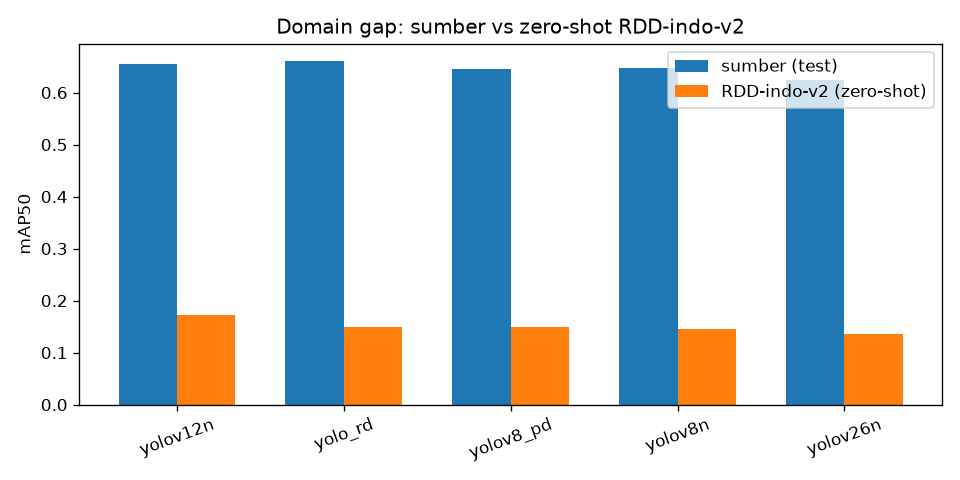

In [11]:
from IPython.display import Image, display
display(Image(str(EV / 'domain_gap.png')))  # fallback agnostik-backend

## ***Visualisasi Prediksi (Sampel Acak)***
---
Sampel acak (seed 42, bukan 6 citra pertama) model terbaik. Sel berikutnya membandingkan GT vs prediksi pada 4 citra acak lain (seed 7).

model visual: yolov12n mAP50=0.172


sampel acak: ['Merge-1_mp4-0440_jpg.rf.', 'Merge-1_mp4-0072_jpg.rf.', 'Merge-1_mp4-0764_jpg.rf.', 'Merge-1_mp4-0729_jpg.rf.', 'Merge-1_mp4-0713_jpg.rf.', 'Merge-1_mp4-0503_jpg.rf.']


<Figure size 1200x800 with 6 Axes>

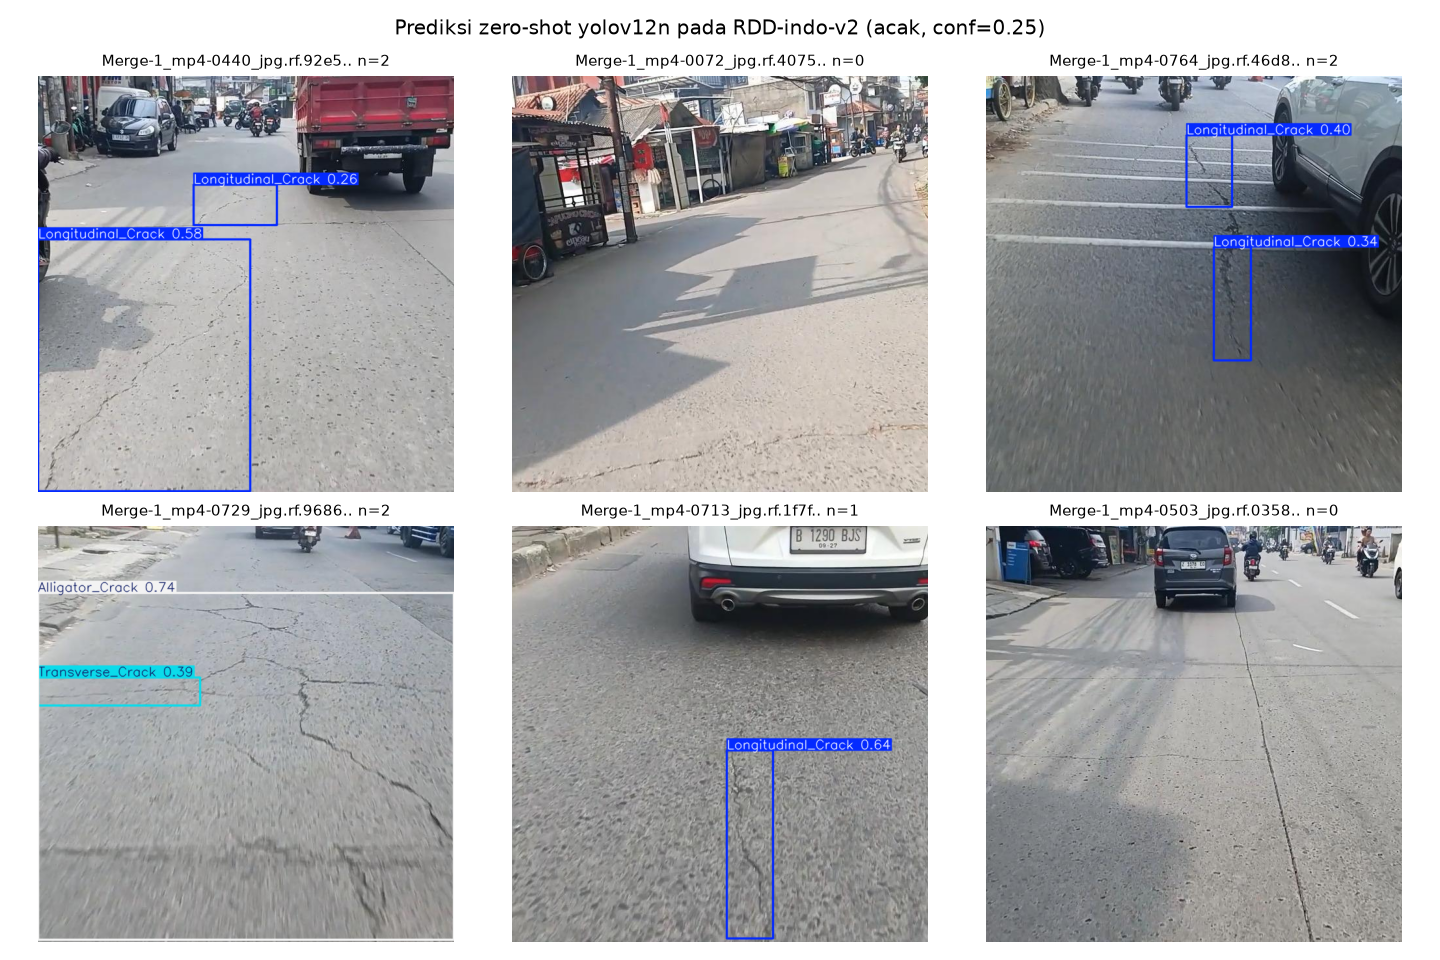

In [12]:
import random
from IPython.display import Image as IPImage, display

PRED_SEED = 42
best = max(ZS, key=lambda k: ZS[k]['mAP50'])
print('model visual:', best, f"mAP50={ZS[best]['mAP50']:.3f}")
bm = YOLO(str(WEIGHTS[best]))
all_imgs = sorted((REM / 'test/images').glob('*'))
imgs = random.Random(PRED_SEED).sample(all_imgs, 6)
print('sampel acak:', [p.name[:24] for p in imgs])
res = bm.predict([str(p) for p in imgs], imgsz=640, conf=0.25, iou=0.6, verbose=False, device=DEVICE)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for a, r, p in zip(ax.flat, res, imgs):
    a.imshow(r.plot()[:, :, ::-1])
    a.set_title(f"{p.name[:28]}.. n={len(r.boxes)}", fontsize=9)
    a.axis('off')
plt.suptitle(f'Prediksi zero-shot {best} pada RDD-indo-v2 (acak, conf=0.25)')
plt.tight_layout()
plt.savefig(str(EV / 'zs_samples_pred_only.png'), dpi=120)
plt.show()
display(IPImage(str(EV / 'zs_samples_pred_only.png')))  # fallback agnostik-backend

### ***GT vs Prediksi (Sampel Acak)***
Kiri: ground-truth (label remap). Kanan: prediksi model terbaik. 4 citra acak seed 7.

sampel acak GT vs Pred: ['Merge-1_mp4-0834_jpg.rf.', 'Merge-1_mp4-0552_jpg.rf.', 'Merge-1_mp4-1097_jpg.rf.', 'Merge-1_mp4-0315_jpg.rf.']


<Figure size 1200x1600 with 8 Axes>

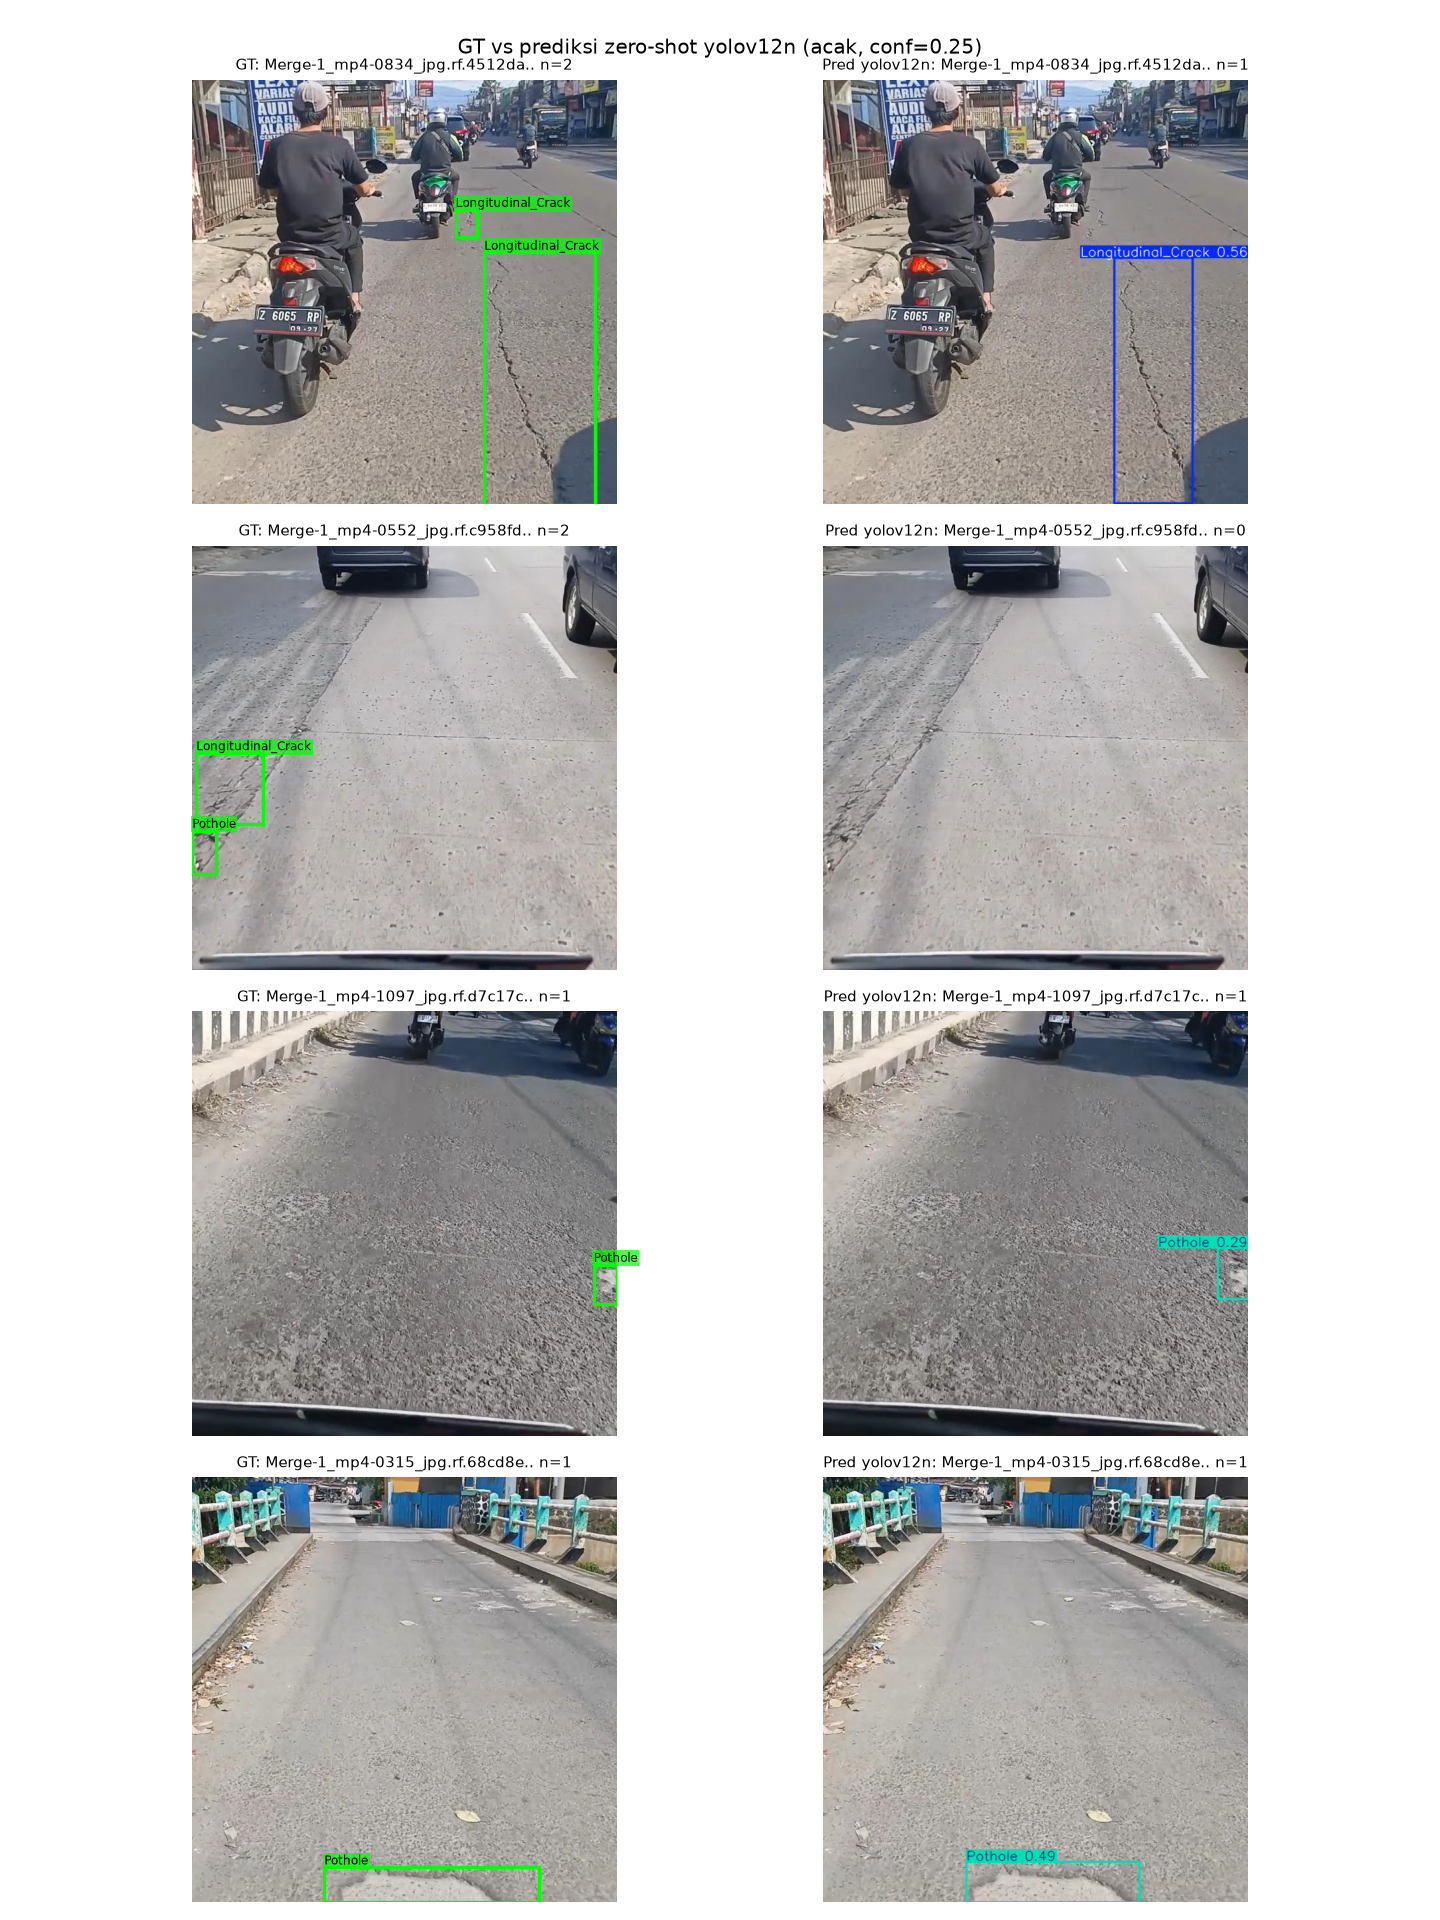

In [13]:
import random
from PIL import Image as PILImage
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from IPython.display import Image as IPImage, display
from ultralytics import YOLO

GT_SEED = 7
best_gt = max(ZS, key=lambda k: ZS[k]['mAP50'])
bmg = YOLO(str(WEIGHTS[best_gt]))
gt_imgs = random.Random(GT_SEED).sample(sorted((REM / 'test/images').glob('*')), 4)
print('sampel acak GT vs Pred:', [p.name[:24] for p in gt_imgs])
res_g = bmg.predict([str(p) for p in gt_imgs], imgsz=640, conf=0.25, iou=0.6, verbose=False, device=DEVICE)

GT_COLOR = 'lime'
fig, axes = plt.subplots(4, 2, figsize=(12, 16))
for row, (p, r) in enumerate(zip(gt_imgs, res_g)):
    im = PILImage.open(p).convert('RGB')
    W, H = im.size
    ax_gt, ax_pr = axes[row]
    ax_gt.imshow(im)
    n_gt = 0
    for l in (REM / 'test/labels' / (p.stem + '.txt')).read_text().splitlines():
        if not l.strip():
            continue
        q = l.split()
        cid, x, y, w, h = int(q[0]), *map(float, q[1:5])
        x0, y0 = (x - w / 2) * W, (y - h / 2) * H
        ax_gt.add_patch(patches.Rectangle((x0, y0), w * W, h * H, linewidth=2, edgecolor=GT_COLOR, facecolor='none'))
        ax_gt.text(x0, max(y0 - 4, 0), SRC_NAMES[cid], fontsize=7, color='black',
                   bbox=dict(facecolor=GT_COLOR, alpha=0.7, pad=1, edgecolor='none'))
        n_gt += 1
    ax_gt.set_title(f"GT: {p.name[:30]}.. n={n_gt}", fontsize=9)
    ax_gt.axis('off')
    ax_pr.imshow(r.plot()[:, :, ::-1])
    ax_pr.set_title(f"Pred {best_gt}: {p.name[:30]}.. n={len(r.boxes)}", fontsize=9)
    ax_pr.axis('off')
plt.suptitle(f'GT vs prediksi zero-shot {best_gt} (acak, conf=0.25)')
plt.tight_layout()
plt.savefig(str(EV / 'zs_samples_gt_vs_pred.png'), dpi=120)
plt.show()
display(IPImage(str(EV / 'zs_samples_gt_vs_pred.png')))  # fallback agnostik-backend

## ***Kesimpulan Sementara***
---
(Diisi setelah eksekusi — lihat output sel Domain Gap dan Visualisasi di atas.)